In [1]:
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import linregress

# Importing the zams tables of the MESA for future work 

In [3]:
mesa_low_zams= pd.read_csv("D:\\paper\\low_zams_table.csv", index_col=0, comment="#", skipinitialspace=True, skip_blank_lines=True, dtype={
})
mesa_inter_zams= pd.read_csv("D:\\paper\\inter_zams_table.csv", index_col=0, comment="#", skipinitialspace=True, skip_blank_lines=True, dtype={
})
mesa_high_zams= pd.read_csv("D:\\paper\\high_zams_table.csv", index_col=0, comment="#", skipinitialspace=True, skip_blank_lines=True, dtype={
})
simulated_zams = pd.concat([mesa_low_zams, mesa_inter_zams, mesa_high_zams], axis=0)
simulated_zams = simulated_zams.sort_values(by=["star_mass"])

In [4]:
files = sorted(glob.glob(r"D:\paper\validation\mist_tracks" + "/*.eep"))
print("MIST files found:", len(files))

MIST files found: 17


In [5]:
rows = []
for f in files:
    with open(f) as fh:
        lines = fh.readlines()

    n_hdr = 0
    while lines[n_hdr].startswith("#"):
        n_hdr += 1
    hdr = lines[:n_hdr]
    colnames = hdr[-1].lstrip("#").split()

    # initial mass: the line right after the '# initial_mass ...' label line
    m_init = None
    for k, line in enumerate(hdr):
        if "initial_mass" in line:
            m_init = float(hdr[k + 1].split()[1])
            break

    # ZAMS EEP: second number in the '# EEPs:' line
    zams_eep = None
    for line in hdr:
        if "EEPs:" in line:
            zams_eep = int(line.split("EEPs:")[1].split()[1])
            break

    if m_init is None or zams_eep is None:
        print("skipping (header not understood):", f)
        continue

    df = pd.read_csv(f, sep=r"\s+", skiprows=n_hdr, names=colnames, header=None)
    if len(df) < zams_eep:
        print("skipping (track ends before ZAMS):", f)
        continue
    z = df.iloc[zams_eep - 1]
    rows.append([m_init, z["star_age"], z["log_Teff"], z["log_L"], z["log_R"]])


In [6]:
mist = pd.DataFrame(rows, columns=["mass", "age", "logT", "logL", "logR"])
mist = mist.sort_values("mass").reset_index(drop=True)
print(mist.round(4).to_string(index=False))


 mass          age   logT    logL    logR
  0.8 2.599990e+07 3.8010 -0.2028 -0.1807
  1.0 1.625823e+07 3.8625  0.2432 -0.0807
  1.2 1.173267e+07 3.9317  0.5926 -0.0443
  1.5 7.228839e+06 4.0221  0.9970 -0.0230
  2.0 3.821234e+06 4.1295  1.4878  0.0076
  3.0 1.481179e+06 4.2624  2.1318  0.0637
  4.0 7.651926e+05 4.3347  2.5556  0.1311
  5.0 4.777676e+05 4.3837  2.8728  0.1916
  6.0 3.299820e+05 4.4221  3.1289  0.2430
  7.0 2.448815e+05 4.4529  3.3397  0.2868
  8.0 1.948527e+05 4.4779  3.5161  0.3249
 10.0 1.335724e+05 4.5196  3.8087  0.3878
 15.0 7.311929e+04 4.5900  4.3115  0.4985
 20.0 5.089143e+04 4.6357  4.6446  0.5735
 25.0 4.015456e+04 4.6683  4.8866  0.6294
 40.0 2.708437e+04 4.7276  5.3531  0.7441
 50.0 2.356336e+04 4.7510  5.5536  0.7975


In [7]:
simulated_zams["key"] = simulated_zams["star_mass"].round(3)
mist["key"] = mist["mass"].round(3)
comp = simulated_zams.merge(mist, on="key", suffixes=("_mesa", "_mist"))

comp["dlogL"] = comp["logL_mesa"] - comp["logL_mist"]
def mesa_column(*names):
    """Combine alternate MESA column names and convert values to numbers."""
    result = pd.Series(np.nan, index=simulated_zams.index, dtype=float)
    for name in names:
        if name in simulated_zams.columns:
            values = pd.to_numeric(
                simulated_zams[name].astype(str).str.replace(",", "", regex=False),
                errors="coerce",
            )
            result = result.combine_first(values)
    return result

mesa_comp = pd.DataFrame({
    "key": mesa_column("star_mass", "Star mass").round(3),
    "mass_mesa": mesa_column("star_mass", "Star mass"),
    "age_mesa": mesa_column("star_age", "Star age"),
    "logT_mesa": mesa_column("log_Teff", "logT_eff"),
    "logL_mesa": mesa_column("log_L", "logL"),
    "logR_mesa": mesa_column("log_R", "logR"),
})

mist_comp = mist.rename(columns={
    "mass": "mass_mist",
    "age": "age_mist",
    "logT": "logT_mist",
    "logL": "logL_mist",
    "logR": "logR_mist",
}).copy()
mist_comp["key"] = mist_comp["mass_mist"].round(3)

comp = mesa_comp.merge(mist_comp, on="key", how="inner")
comp["dlogL"] = comp["logL_mesa"] - comp["logL_mist"]
comp["dlogT"] = comp["logT_mesa"] - comp["logT_mist"]
comp["dlogR"] = comp["logR_mesa"] - comp["logR_mist"]
comp["age_ratio"] = comp["age_mesa"] / comp["age_mist"]

out = comp[["mass_mesa", "dlogL", "dlogT", "dlogR", "age_ratio"]].copy()
out.columns = ["M (Msun)", "dlogL", "dlogTeff", "dlogR", "age MESA / MIST"]
print(out.round(3).to_string(index=False))
out.round(4).to_csv("zams_offsets_vs_mist.csv", index=False)

missing = sorted(set(mesa_comp["key"].dropna()) - set(mist_comp["key"].dropna()))
if missing:
    print("masses with no MIST track:", missing)
comp["dlogR"] = comp["logR_mesa"] - comp["logR_mist"]
comp["age_ratio"] = comp["age_mesa"] / comp["age_mist"]

out = comp[["mass_mesa", "dlogL", "dlogT", "dlogR", "age_ratio"]].copy()
out.columns = ["M (Msun)", "dlogL", "dlogTeff", "dlogR", "age MESA / MIST"]
print()
print(out.round(3).to_string(index=False))
out.round(4).to_csv("zams_offsets_vs_mist.csv", index=False)

missing = sorted(set(simulated_zams["key"]) - set(mist["key"]))
if len(missing) > 0:
    print("masses with no MIST track:", missing)

 M (Msun)  dlogL  dlogTeff  dlogR  age MESA / MIST
      0.8 -0.004    -0.009  0.015            1.084
      1.0  0.039    -0.003  0.025           49.558
      1.2  0.025     0.002  0.009           32.324
      1.5  0.007    -0.001  0.005           17.089
      2.0 -0.009    -0.004  0.003            6.556
     10.0 -0.013    -0.011  0.014            1.029
     15.0 -0.021    -0.015  0.019            1.980
     20.0 -0.022    -0.014  0.018            1.388
     25.0 -0.018    -0.014  0.020            2.051
     40.0 -0.014    -0.014  0.021            2.374
     50.0 -0.013    -0.013  0.021            1.522
      3.0 -0.027    -0.010  0.007            1.195
      4.0 -0.025    -0.016  0.019            2.188
      5.0 -0.025    -0.015  0.018            1.715
      6.0 -0.028    -0.015  0.016            1.411
      7.0 -0.029    -0.015  0.015            1.281
      8.0 -0.022    -0.015  0.019            2.028

 M (Msun)  dlogL  dlogTeff  dlogR  age MESA / MIST
      0.8 -0.004    -0.009  0.


           regime  N  slope MESA   err  intercept MESA  slope MIST   err  intercept MIST  difference  combined err  n sigma  R2 MESA  R2 MIST
         Low mass  5       4.199 0.147           0.249       4.244 0.085           0.234      -0.045          0.17    0.265    0.996    0.999
Intermediate mass  6       3.254 0.028           0.564       3.252 0.029           0.591       0.002          0.04    0.052    1.000    1.000
        High mass  6       2.489 0.067           1.351       2.484 0.074           1.374       0.005          0.10    0.050    0.997    0.996
NOTE: Low mass slope differs from MIST by 0.3 sigma
NOTE: Intermediate mass slope differs from MIST by 0.1 sigma
NOTE: High mass slope differs from MIST by 0.1 sigma
NOTE: Low mass slope differs from MIST by 0.3 sigma
NOTE: Intermediate mass slope differs from MIST by 0.1 sigma
NOTE: High mass slope differs from MIST by 0.1 sigma
NOTE: Low mass slope differs from MIST by 0.3 sigma
NOTE: Intermediate mass slope differs from MIST

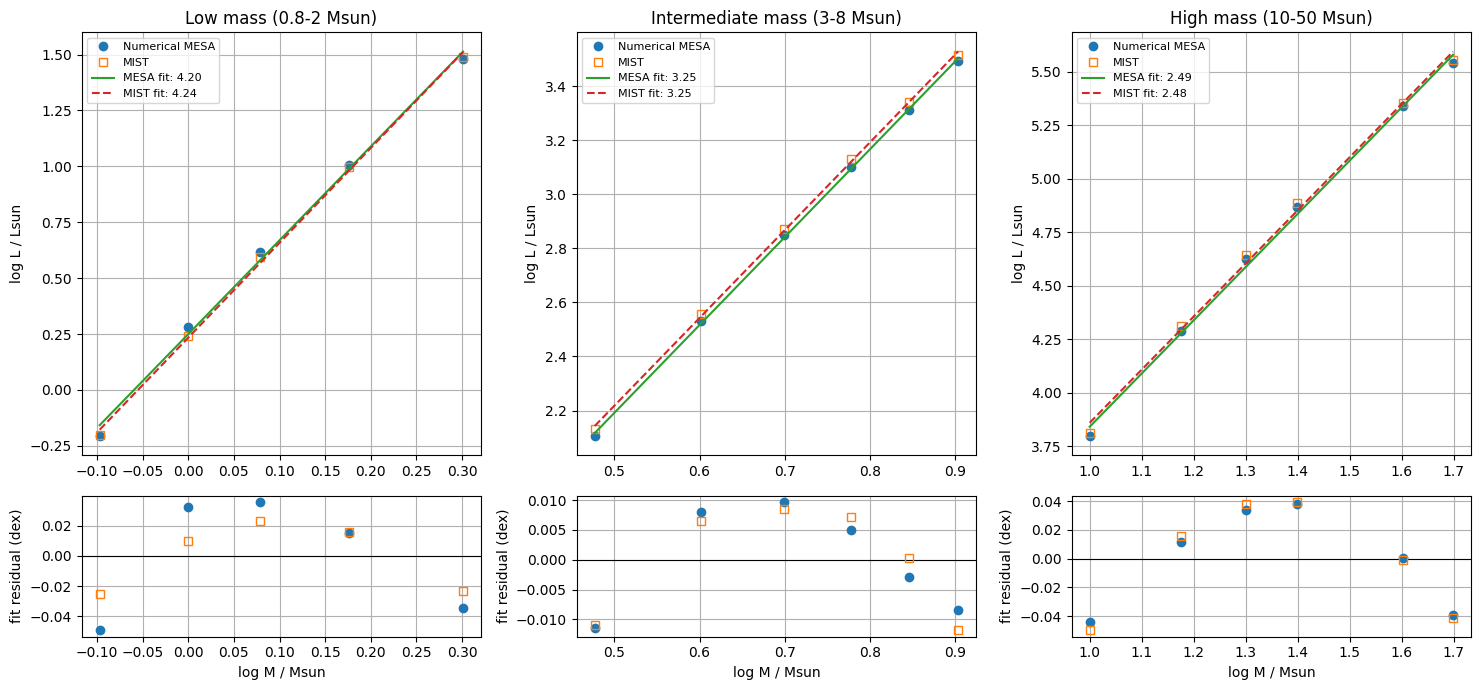

In [11]:
regimes = [("Low mass", 0.8, 2.0),
           ("Intermediate mass", 3.0, 8.0),
           ("High mass", 10.0, 50.0)]
slope_rows = []
fig, axes = plt.subplots(2, 3, figsize=(15, 7),
                         gridspec_kw={"height_ratios": [3, 1]})

for i, (name, mmin, mmax) in enumerate(regimes):
    a = comp[(comp["mass_mesa"] >= mmin) & (comp["mass_mesa"] <= mmax)]
    if len(a) < 3:
        print(name, ": fewer than 3 common points, skipping")
        continue

    x = np.log10(a["mass_mesa"].values)
    ya = a["logL_mesa"].values
    yb = a["logL_mist"].values

    fa = linregress(x, ya)
    fb = linregress(x, yb)

    diff = fa.slope - fb.slope
    err = np.sqrt(fa.stderr**2 + fb.stderr**2)
    nsig = abs(diff) / err

    slope_rows.append([name, len(a), fa.slope, fa.stderr, fa.intercept,
                       fb.slope, fb.stderr, fb.intercept, diff, err, nsig,
                       fa.rvalue**2, fb.rvalue**2])

    ax = axes[0, i]
    xx = np.linspace(x.min(), x.max(), 50)
    ax.plot(x, ya, "o", label="Numerical MESA")
    ax.plot(x, yb, "s", mfc="none", label="MIST")
    ax.plot(xx, fa.slope * xx + fa.intercept, "-",
            label="MESA fit: %.2f" % fa.slope)
    ax.plot(xx, fb.slope * xx + fb.intercept, "--",
            label="MIST fit: %.2f" % fb.slope)
    ax.set_title(name + " (%g-%g Msun)" % (mmin, mmax))
    ax.set_ylabel("log L / Lsun")
    ax.grid()
    ax.legend(fontsize=8)

    ax = axes[1, i]
    ax.axhline(0, color="k", lw=0.8)
    ax.plot(x, ya - (fa.slope * x + fa.intercept), "o")
    ax.plot(x, yb - (fb.slope * x + fb.intercept), "s", mfc="none")
    ax.grid()
    ax.set_xlabel("log M / Msun")
    ax.set_ylabel("fit residual (dex)")

plt.tight_layout()
plt.savefig("ml_fits_vs_mist.png", dpi=300)

cols = ["regime", "N", "slope MESA", "err", "intercept MESA",
        "slope MIST", "err", "intercept MIST",
        "difference", "combined err", "n sigma", "R2 MESA", "R2 MIST"]
slopes = pd.DataFrame(slope_rows, columns=cols)
print()
print(slopes.round(3).to_string(index=False))
slopes.round(4).to_csv("slope_comparison_vs_mist.csv", index=False)

for r in slope_rows:
    sigma_limit = 3.0  # report only differences larger than 3 sigma

    for r in slope_rows:
        if r[10] > sigma_limit:
            print("NOTE:", r[0], "slope differs from MIST by %.1f sigma" % r[10])
        print("NOTE:", r[0], "slope differs from MIST by %.1f sigma" % r[10])

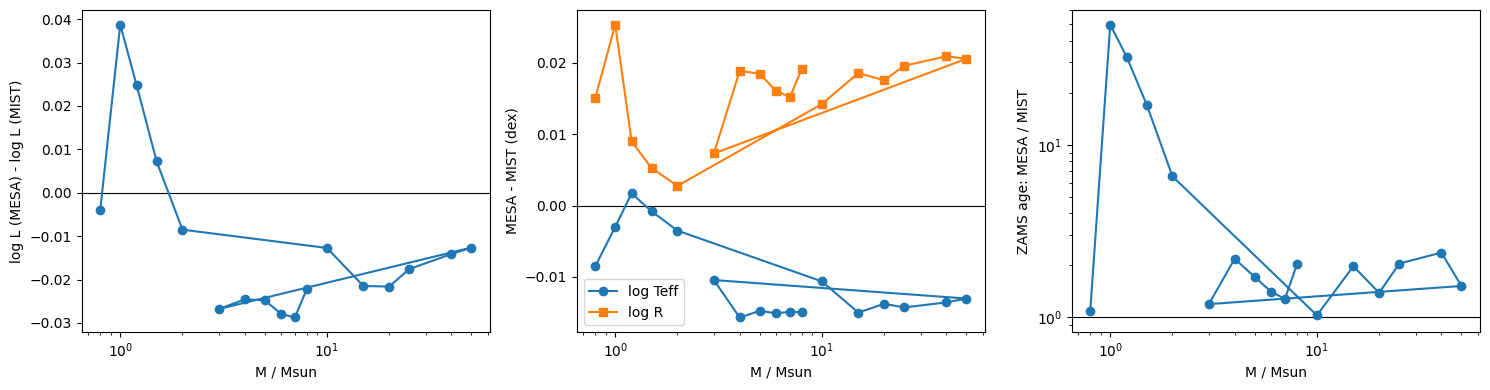

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].axhline(0, color="k", lw=0.8)
axes[0].plot(comp["mass_mesa"], comp["dlogL"], "o-")
axes[0].set_xscale("log")
axes[0].set_xlabel("M / Msun")
axes[0].set_ylabel("log L (MESA) - log L (MIST)")

axes[1].axhline(0, color="k", lw=0.8)
axes[1].plot(comp["mass_mesa"], comp["dlogT"], "o-", label="log Teff")
axes[1].plot(comp["mass_mesa"], comp["dlogR"], "s-", label="log R")
axes[1].set_xscale("log")
axes[1].set_xlabel("M / Msun")
axes[1].set_ylabel("MESA - MIST (dex)")
axes[1].legend()

axes[2].axhline(1, color="k", lw=0.8)
axes[2].plot(comp["mass_mesa"], comp["age_ratio"], "o-")
axes[2].set_xscale("log")
axes[2].set_yscale("log")
axes[2].set_xlabel("M / Msun")
axes[2].set_ylabel("ZAMS age: MESA / MIST")

plt.tight_layout()
plt.savefig("zams_offsets_vs_mist.png", dpi=300)
plt.show()